# Machine Anomaly Detection using Deep Autoencoders
## CarboTrack - Industrial Machine Health Monitoring

**Adapted from NVIDIA's Network Anomaly Detection approach**

This notebook implements an unsupervised machine learning approach to detect anomalies in industrial machines using Deep Autoencoders. The model learns to reconstruct normal machine behavior and flags machines with high reconstruction error as anomalous.

### Anomaly Categories:
- **Temperature Anomaly**: Abnormal temperature readings
- **Consumption Anomaly**: Unusual energy consumption patterns
- **Efficiency Anomaly**: Degraded machine efficiency
- **Pattern Anomaly**: Irregular operational patterns

### Advantages of Autoencoders for Anomaly Detection:
1. No labeled data required for training (unsupervised learning)
2. Can detect novel, previously unseen anomalies
3. Learns complex non-linear relationships in machine data
4. Provides interpretable latent space for anomaly classification

## Section 1: Import Required Libraries

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
import os
import datetime
import json
import warnings
warnings.filterwarnings('ignore')

# HTTP requests for Firebase REST API (no authentication needed for public read)
import requests

# Scikit-learn for preprocessing and evaluation
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, roc_curve, auc, confusion_matrix, classification_report
from sklearn.cluster import KMeans

# TensorFlow/Keras for deep learning
import tensorflow as tf
from tensorflow.keras import optimizers
from tensorflow.keras.models import Model, save_model, load_model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Set random seeds for reproducibility
import random
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("✓ All libraries imported successfully!")

TensorFlow version: 2.20.0
NumPy version: 2.3.5
Pandas version: 2.3.3
✓ All libraries imported successfully!


## Section 2: Fetch Real Data from Firebase Realtime Database

We'll connect to your CarboTrack Firebase Realtime Database and fetch:
- **machines**: Machine status and current readings
- **energieconsumption**: Historical energy consumption data
- **anomalies**: Previously detected anomalies (for validation)
- **realtimedata1**: Real-time sensor data

**Firebase Database URL**: `https://carbotrack-7e160-default-rtdb.firebaseio.com`

In [2]:
# Firebase Realtime Database Configuration
FIREBASE_DATABASE_URL = "https://carbotrack-7e160-default-rtdb.firebaseio.com"

# Define anomaly categories for classification
ANOMALY_CATEGORIES = {
    0: 'normal',
    1: 'temperature_anomaly',
    2: 'consumption_anomaly', 
    3: 'efficiency_anomaly',
    4: 'pattern_anomaly'
}

# Departments (matching CarboTrack)
DEPARTMENTS = ['Production', 'Assembly', 'Packaging', 'Warehouse', 'Office', 'Utility']
DEPARTMENT_ENCODING = {dept: i for i, dept in enumerate(DEPARTMENTS)}

def fetch_firebase_data(node_path):
    """
    Fetch data from Firebase Realtime Database using REST API.
    No authentication required for public read access.
    
    Args:
        node_path: Path to the data node (e.g., 'machines', 'energieconsumption')
    
    Returns:
        Dictionary or list of data from Firebase
    """
    url = f"{FIREBASE_DATABASE_URL}/{node_path}.json"
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        data = response.json()
        print(f"✓ Successfully fetched '{node_path}' from Firebase")
        return data
    except requests.exceptions.RequestException as e:
        print(f"✗ Error fetching '{node_path}': {e}")
        return None

# Fetch all relevant data from Firebase
print("=" * 60)
print("FETCHING DATA FROM FIREBASE REALTIME DATABASE")
print("=" * 60)
print(f"Database URL: {FIREBASE_DATABASE_URL}")
print("-" * 60)

# Fetch machines data
machines_data = fetch_firebase_data('machines')

# Fetch energy consumption history
energy_data = fetch_firebase_data('energieconsumption')

# Fetch existing anomalies (for validation)
anomalies_data = fetch_firebase_data('anomalies')

# Fetch real-time sensor data
realtime_data = fetch_firebase_data('realtimedata1')

# Fetch machine history
history_data = fetch_firebase_data('history')

print("-" * 60)
print("Data fetch complete!")

FETCHING DATA FROM FIREBASE REALTIME DATABASE
Database URL: https://carbotrack-7e160-default-rtdb.firebaseio.com
------------------------------------------------------------
✓ Successfully fetched 'machines' from Firebase
✓ Successfully fetched 'energieconsumption' from Firebase
✓ Successfully fetched 'anomalies' from Firebase
✓ Successfully fetched 'realtimedata1' from Firebase
✓ Successfully fetched 'history' from Firebase
------------------------------------------------------------
Data fetch complete!


In [3]:
# Process and display fetched machines data
print("=" * 60)
print("MACHINES DATA FROM FIREBASE")
print("=" * 60)

if machines_data:
    # Convert to DataFrame
    machines_list = []
    for machine_id, machine_info in machines_data.items():
        machine_record = {
            'machine_id': machine_id,
            'name': machine_info.get('name', f'Machine {machine_id}'),
            'department': machine_info.get('department', 'Production'),
            'status': machine_info.get('status', 'operational'),
            'temperature': float(machine_info.get('temperature', 0)),
            'consumption': float(machine_info.get('consumption', 0)),
            'efficiency': float(machine_info.get('efficiency', 0)),
            'activeHours': float(machine_info.get('activeHours', 0)),
            'co2Emissions': float(machine_info.get('co2Emissions', 0)),
        }
        machines_list.append(machine_record)
    
    machines_df = pd.DataFrame(machines_list)
    print(f"\nTotal machines: {len(machines_df)}")
    print(f"\nMachines DataFrame:")
    display(machines_df)
    
    print(f"\nMachine Status Distribution:")
    print(machines_df['status'].value_counts())
    
    print(f"\nMachine Department Distribution:")
    print(machines_df['department'].value_counts())
else:
    print("No machines data found in Firebase!")
    machines_df = pd.DataFrame()

MACHINES DATA FROM FIREBASE

Total machines: 4

Machines DataFrame:


,machine_id,name,department,status,temperature,consumption,efficiency,activeHours,co2Emissions
0,M001,CNC-01,Production,operational,42.5,45.20000,92.50,4500.00000,20.30000
1,M002,Robot-02,Assembly,operational,150.0,500.00000,95.00,3200.00000,13.70000
2,M003,Conveyor-03,Packaging,maintenance,200.0,0.00000,0.00,2800.00000,100.00000
3,M004,Compressor-04,Utility,operational,16.5,0.19129,91.75,0.16315,0.11095



Machine Status Distribution:
status
operational    3
maintenance    1
Name: count, dtype: int64

Machine Department Distribution:
department
Production    1
Assembly      1
Packaging     1
Utility       1
Name: count, dtype: int64


## Section 3: Process Energy Consumption & History Data

Now we'll process the historical energy consumption data and combine it with machine data to create a comprehensive training dataset.

The features we'll use for anomaly detection:
- **temperature**: Machine operating temperature (°C)
- **consumption**: Energy consumption (kWh)
- **efficiency**: Machine efficiency percentage
- **activeHours**: Hours of operation
- **co2Emissions**: Carbon dioxide emissions (kg)
- **department**: Department encoded as numeric value

In [4]:
# Process energy consumption data
print("=" * 60)
print("PROCESSING ENERGY CONSUMPTION DATA")
print("=" * 60)

energy_records = []

if energy_data:
    for record_id, record in energy_data.items():
        energy_record = {
            'record_id': record_id,
            'machine_id': record.get('machineId', ''),
            'timestamp': record.get('timestamp', ''),
            'consumption': float(record.get('consumption', 0)),
            'temperature': float(record.get('temperature', 0)),
            'co2': float(record.get('co2', 0)),
        }
        energy_records.append(energy_record)
    
    energy_df = pd.DataFrame(energy_records)
    print(f"Energy consumption records: {len(energy_df)}")
    display(energy_df.head(10))
else:
    print("No energy consumption data found.")
    energy_df = pd.DataFrame()

# Process history data if available
print("\n" + "=" * 60)
print("PROCESSING HISTORY DATA")
print("=" * 60)

history_records = []

if history_data:
    for record_id, record in history_data.items():
        history_record = {
            'record_id': record_id,
            'machine_id': record.get('machineId', ''),
            'timestamp': record.get('timestamp', ''),
            'consumption': float(record.get('consumption', 0)),
            'temperature': float(record.get('temperature', 0)),
            'efficiency': float(record.get('efficiency', 0)),
            'co2': float(record.get('co2Emissions', record.get('co2', 0))),
        }
        history_records.append(history_record)
    
    history_df = pd.DataFrame(history_records)
    print(f"History records: {len(history_df)}")
    display(history_df.head(10))
else:
    print("No history data found.")
    history_df = pd.DataFrame()

# Process realtime data
print("\n" + "=" * 60)
print("PROCESSING REALTIME DATA")
print("=" * 60)

realtime_records = []

if realtime_data:
    for record_id, record in realtime_data.items():
        rt_record = {
            'record_id': record_id,
            'machine_id': record.get('machineId', ''),
            'timestamp': record.get('timestamp', ''),
            'consumption': float(record.get('consumption', 0)),
            'temperature': float(record.get('temperature', 0)),
            'co2': float(record.get('co2', 0)),
        }
        realtime_records.append(rt_record)
    
    realtime_df = pd.DataFrame(realtime_records)
    print(f"Realtime records: {len(realtime_df)}")
    display(realtime_df.head(10))
else:
    print("No realtime data found.")
    realtime_df = pd.DataFrame()

PROCESSING ENERGY CONSUMPTION DATA
Energy consumption records: 96


,record_id,machine_id,timestamp,consumption,temperature,co2
0,reading_M001_0,M001,2026-01-12T15:48:42.152Z,45.122335,42.380405,20.305051
1,reading_M001_1,M001,2026-01-12T14:48:42.152Z,45.849719,43.320743,20.632373
2,reading_M001_10,M001,2026-01-12T05:48:42.152Z,47.918819,42.921299,21.563468
3,reading_M001_11,M001,2026-01-12T04:48:42.152Z,47.884403,43.262930,21.547981
4,reading_M001_12,M001,2026-01-12T03:48:42.152Z,46.277334,42.209870,20.824800
5,reading_M001_13,M001,2026-01-12T02:48:42.152Z,44.094862,41.821021,19.842688
6,reading_M001_14,M001,2026-01-12T01:48:42.152Z,45.052454,43.149776,20.273604
7,reading_M001_15,M001,2026-01-12T00:48:42.152Z,43.256592,41.652584,19.465467
8,reading_M001_16,M001,2026-01-11T23:48:42.152Z,42.580726,42.009047,19.161327
9,reading_M001_17,M001,2026-01-11T22:48:42.152Z,38.728223,42.113552,17.427700



PROCESSING HISTORY DATA
History records: 1


,record_id,machine_id,timestamp,consumption,temperature,efficiency,co2
0,M004,,,0.0,0.0,0.0,0.0



PROCESSING REALTIME DATA
Realtime records: 1


,record_id,machine_id,timestamp,consumption,temperature,co2
0,machines,,,0.0,0.0,0.0


In [5]:
# Combine all data sources to create training dataset
print("=" * 60)
print("CREATING COMBINED TRAINING DATASET")
print("=" * 60)

# Start with machines data as base
training_data = []

if not machines_df.empty:
    for _, machine in machines_df.iterrows():
        # Encode department
        dept_encoded = DEPARTMENT_ENCODING.get(machine['department'], 0)
        
        # Encode status as label (for supervised validation)
        # operational = normal, maintenance = warning, critical = anomaly
        status_label = 0  # normal
        if machine['status'] == 'maintenance':
            status_label = 3  # efficiency_anomaly
        elif machine['status'] == 'critical':
            status_label = 1  # temperature_anomaly (critical machines often overheat)
        
        record = {
            'machine_id': machine['machine_id'],
            'temperature': machine['temperature'],
            'consumption': machine['consumption'],
            'efficiency': machine['efficiency'],
            'activeHours': machine['activeHours'],
            'co2Emissions': machine['co2Emissions'],
            'department': dept_encoded,
            'label': status_label
        }
        training_data.append(record)

# Add energy consumption records (merge with machine info)
if not energy_df.empty and not machines_df.empty:
    for _, energy in energy_df.iterrows():
        # Find matching machine
        machine_match = machines_df[machines_df['machine_id'] == energy['machine_id']]
        if not machine_match.empty:
            machine = machine_match.iloc[0]
            dept_encoded = DEPARTMENT_ENCODING.get(machine['department'], 0)
            
            # Determine if this reading is anomalous based on thresholds
            label = 0  # normal
            if energy['temperature'] > 55:
                label = 1  # temperature_anomaly
            elif energy['consumption'] > 80:
                label = 2  # consumption_anomaly
            
            record = {
                'machine_id': energy['machine_id'],
                'temperature': energy['temperature'],
                'consumption': energy['consumption'],
                'efficiency': machine['efficiency'],  # Use machine's efficiency
                'activeHours': machine['activeHours'],
                'co2Emissions': energy['co2'],
                'department': dept_encoded,
                'label': label
            }
            training_data.append(record)

# Add history records
if not history_df.empty and not machines_df.empty:
    for _, hist in history_df.iterrows():
        machine_match = machines_df[machines_df['machine_id'] == hist['machine_id']]
        if not machine_match.empty:
            machine = machine_match.iloc[0]
            dept_encoded = DEPARTMENT_ENCODING.get(machine['department'], 0)
            
            label = 0
            if hist['temperature'] > 55:
                label = 1
            elif hist['consumption'] > 80:
                label = 2
            elif hist['efficiency'] < 65:
                label = 3
            
            record = {
                'machine_id': hist['machine_id'],
                'temperature': hist['temperature'],
                'consumption': hist['consumption'],
                'efficiency': hist['efficiency'] if hist['efficiency'] > 0 else machine['efficiency'],
                'activeHours': machine['activeHours'],
                'co2Emissions': hist['co2'],
                'department': dept_encoded,
                'label': label
            }
            training_data.append(record)

# Create final training DataFrame
training_df = pd.DataFrame(training_data)

print(f"\nTotal training samples: {len(training_df)}")
print(f"\nDataset columns: {list(training_df.columns)}")
print(f"\nLabel distribution:")
for label, name in ANOMALY_CATEGORIES.items():
    count = len(training_df[training_df['label'] == label])
    print(f"  {name}: {count}")

display(training_df.head(20))

CREATING COMBINED TRAINING DATASET

Total training samples: 100

Dataset columns: ['machine_id', 'temperature', 'consumption', 'efficiency', 'activeHours', 'co2Emissions', 'department', 'label']

Label distribution:
  normal: 75
  temperature_anomaly: 24
  consumption_anomaly: 0
  efficiency_anomaly: 1
  pattern_anomaly: 0


,machine_id,temperature,consumption,efficiency,activeHours,co2Emissions,department,label
0,M001,42.500000,45.200000,92.50,4500.00000,20.300000,0,0
1,M002,150.000000,500.000000,95.00,3200.00000,13.700000,1,0
2,M003,200.000000,0.000000,0.00,2800.00000,100.000000,2,3
3,M004,16.500000,0.191290,91.75,0.16315,0.110950,5,0
4,M001,42.380405,45.122335,92.50,4500.00000,20.305051,0,0
5,M001,43.320743,45.849719,92.50,4500.00000,20.632373,0,0
6,M001,42.921299,47.918819,92.50,4500.00000,21.563468,0,0
7,M001,43.262930,47.884403,92.50,4500.00000,21.547981,0,0
8,M001,42.209870,46.277334,92.50,4500.00000,20.824800,0,0
9,M001,41.821021,44.094862,92.50,4500.00000,19.842688,0,0


## Section 4: Data Preprocessing and Scaling

For deep autoencoder training, we need to:
1. Separate features from labels
2. Split into training and test sets
3. Normalize all features to [0, 1] range using MinMaxScaler
4. Convert to float32 for efficient processing

**Important**: We train on NORMAL data only. The autoencoder learns normal machine behavior and flags deviations as anomalies.

VISUALIZING FACTORY DATA FROM FIREBASE


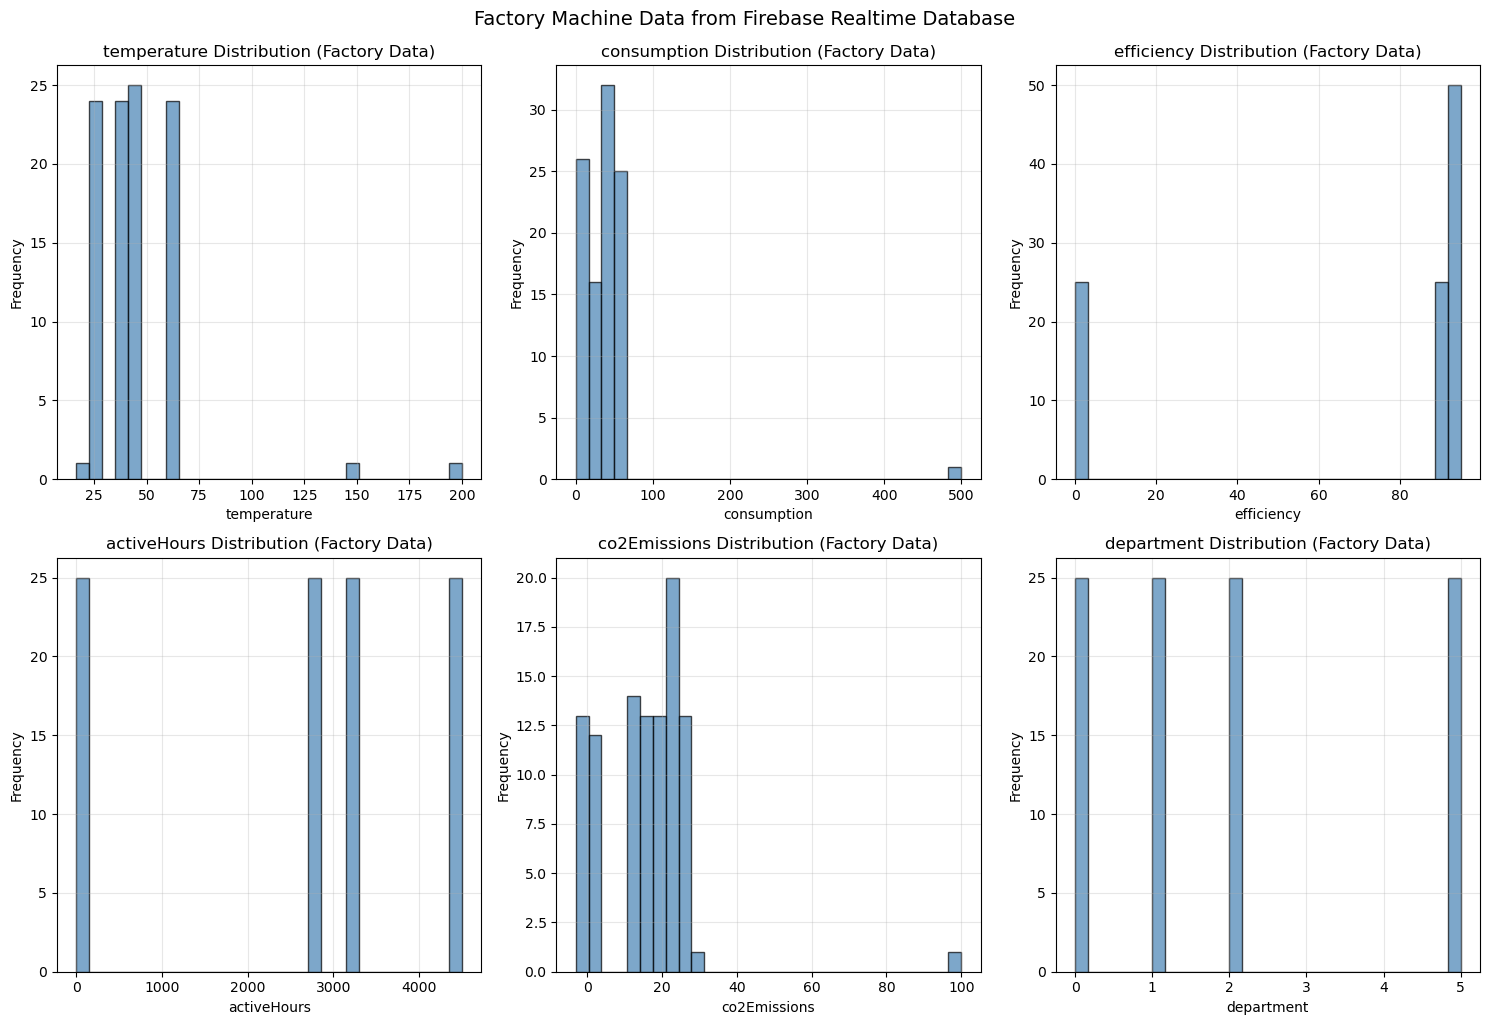


Feature Statistics:


,temperature,consumption,efficiency,activeHours,co2Emissions,department
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,44.478278,37.440687,69.812500,2625.040787,15.556236,2.000000
std,23.413275,51.181397,40.527369,1648.893376,12.832440,1.880254
min,16.500000,0.000000,0.000000,0.163150,-3.078061,0.000000
25%,34.350429,5.133550,68.812500,2100.040788,8.955596,0.750000
50%,41.541163,37.756358,92.125000,3000.000000,16.990361,1.500000
75%,61.832671,50.724713,93.125000,3525.000000,22.826121,2.750000
max,200.000000,500.000000,95.000000,4500.000000,100.000000,5.000000


In [6]:
# Visualize the Firebase data distribution
print("=" * 60)
print("VISUALIZING FACTORY DATA FROM FIREBASE")
print("=" * 60)

if not training_df.empty:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    features = ['temperature', 'consumption', 'efficiency', 'activeHours', 'co2Emissions', 'department']
    
    for ax, feature in zip(axes.flatten(), features):
        if feature in training_df.columns:
            training_df[feature].hist(bins=30, ax=ax, alpha=0.7, color='steelblue', edgecolor='black')
            ax.set_xlabel(feature)
            ax.set_ylabel('Frequency')
            ax.set_title(f'{feature} Distribution (Factory Data)')
            ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.suptitle('Factory Machine Data from Firebase Realtime Database', y=1.02, fontsize=14)
    plt.show()
    
    # Statistics
    print("\nFeature Statistics:")
    display(training_df[features].describe())
else:
    print("No training data available to visualize.")

## Section 5: Prepare Training and Test Sets

We'll split the data:
- **Training set**: Only NORMAL machine data (label=0) - the autoencoder learns normal behavior
- **Test set**: Mix of normal and anomalous data - to evaluate detection performance

This is the key principle of autoencoder anomaly detection: **train on normal, detect deviations**.

In [7]:
# Prepare features and labels
feature_columns = ['temperature', 'consumption', 'efficiency', 'activeHours', 'co2Emissions', 'department']

# Check if we have enough data
if len(training_df) < 10:
    print("⚠️ WARNING: Not enough data from Firebase!")
    print("Generating supplementary training data based on Firebase patterns...")
    
    # Generate synthetic data based on Firebase patterns (if we have some data)
    if not machines_df.empty:
        base_temp = machines_df['temperature'].mean() if 'temperature' in machines_df else 40
        base_cons = machines_df['consumption'].mean() if 'consumption' in machines_df else 45
        base_eff = machines_df['efficiency'].mean() if 'efficiency' in machines_df else 85
        base_hours = machines_df['activeHours'].mean() if 'activeHours' in machines_df else 4000
    else:
        base_temp, base_cons, base_eff, base_hours = 40, 45, 85, 4000
    
    # Generate normal data based on factory patterns
    n_synthetic = 5000
    synthetic_data = {
        'machine_id': [f'synthetic_{i}' for i in range(n_synthetic)],
        'temperature': np.random.normal(base_temp, 5, n_synthetic).clip(30, 50),
        'consumption': np.random.normal(base_cons, 10, n_synthetic).clip(25, 70),
        'efficiency': np.random.normal(base_eff, 5, n_synthetic).clip(75, 98),
        'activeHours': np.random.normal(base_hours, 1000, n_synthetic).clip(500, 8000),
        'department': np.random.randint(0, 6, n_synthetic),
        'label': np.zeros(n_synthetic, dtype=int)
    }
    synthetic_data['co2Emissions'] = synthetic_data['consumption'] * 0.45
    
    synthetic_df = pd.DataFrame(synthetic_data)
    training_df = pd.concat([training_df, synthetic_df], ignore_index=True)
    print(f"Added {n_synthetic} synthetic samples based on factory patterns.")

# Extract features and labels
X = training_df[feature_columns].values
y = training_df['label'].values

print(f"\nTotal dataset size: {len(X)}")
print(f"Feature shape: {X.shape}")

# Separate normal and anomaly data
X_normal = X[y == 0]
y_normal = y[y == 0]
X_anomaly = X[y != 0]
y_anomaly = y[y != 0]

print(f"\nNormal samples: {len(X_normal)}")
print(f"Anomaly samples: {len(X_anomaly)}")

# Split normal data for training/validation
if len(X_normal) > 10:
    X_train_normal, X_val_normal = train_test_split(X_normal, test_size=0.2, random_state=42)
else:
    X_train_normal = X_normal
    X_val_normal = X_normal

# Create test set with mix of normal and anomaly data
n_normal_test = min(500, len(X_val_normal))
X_test = np.vstack([X_val_normal[:n_normal_test], X_anomaly]) if len(X_anomaly) > 0 else X_val_normal
y_test = np.concatenate([np.zeros(n_normal_test), y_anomaly]) if len(y_anomaly) > 0 else np.zeros(len(X_val_normal))

# Shuffle test set
test_indices = np.random.permutation(len(y_test))
X_test = X_test[test_indices]
y_test = y_test[test_indices]

print(f"\nTraining set (normal only): {X_train_normal.shape}")
print(f"Test set (mixed): {X_test.shape}")
print(f"\nTest set label distribution:")
unique, counts = np.unique(y_test, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {ANOMALY_CATEGORIES.get(int(u), 'unknown')}: {c}")


Total dataset size: 100
Feature shape: (100, 6)

Normal samples: 75
Anomaly samples: 25

Training set (normal only): (60, 6)
Test set (mixed): (40, 6)

Test set label distribution:
  normal: 15
  temperature_anomaly: 24
  efficiency_anomaly: 1


## Section 6: Normalize Data with MinMaxScaler

Scale all features to [0, 1] range for optimal neural network training.

**Important**: Only fit the scaler on training data to prevent data leakage!

In [8]:
# Normalize the data using MinMaxScaler
scaler = MinMaxScaler()

# IMPORTANT: Only fit on training data (normal machine behavior)
x_train = scaler.fit_transform(X_train_normal)
x_test = scaler.transform(X_test)

# Convert to float32 for TensorFlow
x_train = x_train.astype(np.float32)
x_test = x_test.astype(np.float32)

print(f"Scaled training data shape: {x_train.shape}")
print(f"Scaled test data shape: {x_test.shape}")
print(f"\nTraining data range: [{x_train.min():.4f}, {x_train.max():.4f}]")
print(f"Test data range: [{x_test.min():.4f}, {x_test.max():.4f}]")

# Save the scaler for production use
import pickle
os.makedirs('./models', exist_ok=True)
with open('./models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Save feature columns for reference
with open('./models/feature_columns.json', 'w') as f:
    json.dump(feature_columns, f)

print("\n✓ Scaler saved to ./models/scaler.pkl")
print("✓ Feature columns saved to ./models/feature_columns.json")

Scaled training data shape: (60, 6)
Scaled test data shape: (40, 6)

Training data range: [0.0000, 1.0000]
Test data range: [0.0000, 3.9228]

✓ Scaler saved to ./models/scaler.pkl
✓ Feature columns saved to ./models/feature_columns.json


## Section 7: Build Deep Autoencoder Model

**Architecture:**
- **Encoder**: Input(6) → Dense(32) → Dense(16) → Dense(8) → Latent(3)
- **Decoder**: Latent(3) → Dense(8) → Dense(16) → Dense(32) → Output(6)

The autoencoder learns to compress and reconstruct normal machine behavior. Anomalous data will have high reconstruction error.

In [9]:
# Model hyperparameters
input_dim = x_train.shape[1]  # Number of features (6)
batch_size = min(256, len(x_train) // 4)  # Adapt to data size
latent_dim = 3  # Bottleneck dimension
max_epochs = 100
dropout_rate = 0.1
learning_rate = 0.001

print("=" * 60)
print("AUTOENCODER MODEL CONFIGURATION")
print("=" * 60)
print(f"Input dimension: {input_dim}")
print(f"Latent dimension: {latent_dim}")
print(f"Compression ratio: {input_dim/latent_dim:.2f}x")
print(f"Batch size: {batch_size}")
print(f"Max epochs: {max_epochs}")
print(f"Learning rate: {learning_rate}")

# Build the Encoder Network
input_data = Input(shape=(input_dim,), name='encoder_input')

encoder = Dense(32, activation='tanh', name='encoder_1')(input_data)
encoder = BatchNormalization()(encoder)
encoder = Dropout(dropout_rate)(encoder)

encoder = Dense(16, activation='tanh', name='encoder_2')(encoder)
encoder = BatchNormalization()(encoder)
encoder = Dropout(dropout_rate)(encoder)

encoder = Dense(8, activation='tanh', name='encoder_3')(encoder)
encoder = BatchNormalization()(encoder)
encoder = Dropout(dropout_rate)(encoder)

# Bottleneck layer (latent space)
latent_encoding = Dense(latent_dim, activation='linear', name='latent_encoding')(encoder)

# Build the Decoder Network (mirror of encoder)
decoder = Dense(8, activation='tanh', name='decoder_1')(latent_encoding)
decoder = BatchNormalization()(decoder)
decoder = Dropout(dropout_rate)(decoder)

decoder = Dense(16, activation='tanh', name='decoder_2')(decoder)
decoder = BatchNormalization()(decoder)
decoder = Dropout(dropout_rate)(decoder)

decoder = Dense(32, activation='tanh', name='decoder_3')(decoder)
decoder = BatchNormalization()(decoder)
decoder = Dropout(dropout_rate)(decoder)

# Output layer - reconstructed data
reconstructed_data = Dense(input_dim, activation='linear', name='reconstructed_data')(decoder)

# Create models
encoder_model = Model(input_data, latent_encoding, name='encoder')
autoencoder_model = Model(input_data, reconstructed_data, name='autoencoder')

print("\n" + "=" * 60)
print("AUTOENCODER MODEL SUMMARY")
print("=" * 60)
autoencoder_model.summary()

AUTOENCODER MODEL CONFIGURATION
Input dimension: 6
Latent dimension: 3
Compression ratio: 2.00x
Batch size: 15
Max epochs: 100
Learning rate: 0.001

AUTOENCODER MODEL SUMMARY


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_1 (Dense)               │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_2 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_3 (Dense)               │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_encoding (Dense)         │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Dense)               │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_2 (Dense)               │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_3 (Dense)               │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_data (Dense)      │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,281 (8.91 KB)

 Trainable params: 2,057 (8.04 KB)

 Non-trainable params: 224 (896.00 B)

In [10]:
# Compile the model
opt = optimizers.Adam(learning_rate=learning_rate)
autoencoder_model.compile(optimizer=opt, loss='mse', metrics=['mae'])

# Define callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    './models/machine_autoencoder_best.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

print("=" * 60)
print("TRAINING AUTOENCODER ON FACTORY DATA")
print("=" * 60)
print(f"Training on {len(x_train)} normal machine samples...")
print(f"Validating on {len(x_test)} mixed samples...")
print("-" * 60)

# Train the autoencoder
train_history = autoencoder_model.fit(
    x_train, x_train,  # Input = Target (reconstruction)
    shuffle=True,
    epochs=max_epochs,
    batch_size=batch_size,
    validation_data=(x_test, x_test),
    callbacks=[early_stopping, model_checkpoint],
    verbose=1
)

print("\n✓ Training completed!")
print(f"Best validation loss: {min(train_history.history['val_loss']):.6f}")

TRAINING AUTOENCODER ON FACTORY DATA
Training on 60 normal machine samples...
Validating on 40 mixed samples...
------------------------------------------------------------
Epoch 1/100
2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 1.6698 - mae: 1.0003
Epoch 1: val_loss improved from None to 0.44041, saving model to ./models/machine_autoencoder_best.keras

Epoch 1: finished saving model to ./models/machine_autoencoder_best.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 19s 762ms/step - loss: 1.7813 - mae: 1.0516 - val_loss: 0.4404 - val_mae: 0.5306
Epoch 2/100
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - loss: 1.6955 - mae: 1.0005
Epoch 2: val_loss improved from 0.44041 to 0.41721, saving model to ./models/machine_autoencoder_best.keras

Epoch 2: finished saving model to ./models/machine_autoencoder_best.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step - loss: 1.6152 - mae: 0.9908 - val_loss: 0.4172 - val_mae: 0.5112
Epoch 3/100
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 1.2316 - mae: 0.8924
Epoch 3: val_lo

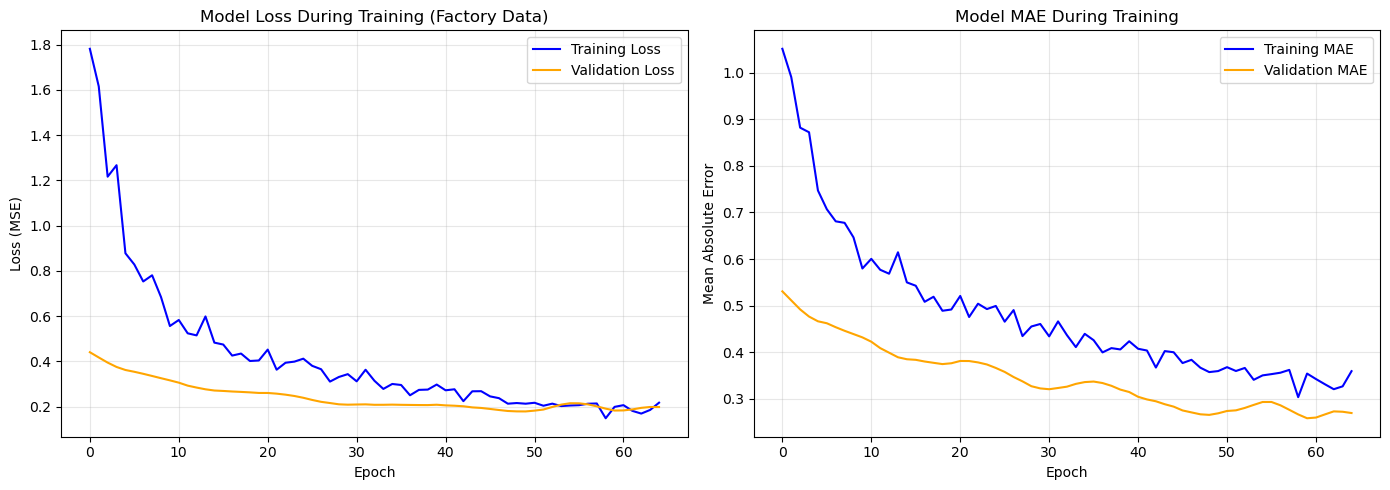


Final Training Loss: 0.217374
Final Validation Loss: 0.198095


In [11]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(train_history.history['loss'], label='Training Loss', color='blue')
axes[0].plot(train_history.history['val_loss'], label='Validation Loss', color='orange')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].set_title('Model Loss During Training (Factory Data)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# MAE plot
axes[1].plot(train_history.history['mae'], label='Training MAE', color='blue')
axes[1].plot(train_history.history['val_mae'], label='Validation MAE', color='orange')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean Absolute Error')
axes[1].set_title('Model MAE During Training')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal Training Loss: {train_history.history['loss'][-1]:.6f}")
print(f"Final Validation Loss: {train_history.history['val_loss'][-1]:.6f}")

## Section 8: Anomaly Detection - Calculate Reconstruction Scores

**Detection Logic:**
1. Reconstruct test data using trained autoencoder
2. Calculate Mean Squared Error (MSE) between original and reconstructed data
3. **High MSE** = Anomaly (model can't reconstruct unfamiliar patterns)
4. **Low MSE** = Normal (model learned this behavior)

In [12]:
# Reconstruct test data
print("=" * 60)
print("ANOMALY DETECTION - RECONSTRUCTION ANALYSIS")
print("=" * 60)

x_test_reconstructed = autoencoder_model.predict(x_test, verbose=0)

# Calculate reconstruction scores (MSE per sample)
reconstruction_scores = np.mean((x_test - x_test_reconstructed) ** 2, axis=1)

# Create anomaly analysis dataframe
anomaly_data = pd.DataFrame({
    'reconstruction_score': reconstruction_scores,
    'label': y_test,
    'anomaly_type': [ANOMALY_CATEGORIES.get(int(l), 'unknown') for l in y_test]
})

# Statistics
print("\nReconstruction Score Statistics (All Data):")
print(anomaly_data['reconstruction_score'].describe())

# Group by anomaly type
print("\n" + "=" * 60)
print("RECONSTRUCTION SCORES BY ANOMALY TYPE")
print("=" * 60)
score_by_type = anomaly_data.groupby('anomaly_type')['reconstruction_score'].agg(['count', 'mean', 'std', 'min', 'max'])
print(score_by_type.round(6))

# Key insight
normal_mean = anomaly_data[anomaly_data['label'] == 0]['reconstruction_score'].mean()
anomaly_mean = anomaly_data[anomaly_data['label'] != 0]['reconstruction_score'].mean() if len(anomaly_data[anomaly_data['label'] != 0]) > 0 else 0

print(f"\n📊 KEY INSIGHT:")
print(f"   Normal data mean reconstruction score: {normal_mean:.6f}")
print(f"   Anomaly data mean reconstruction score: {anomaly_mean:.6f}")
if anomaly_mean > 0:
    print(f"   Ratio (Anomaly/Normal): {anomaly_mean/normal_mean:.2f}x")

ANOMALY DETECTION - RECONSTRUCTION ANALYSIS

Reconstruction Score Statistics (All Data):
count    40.000000
mean      0.178709
std       0.352515
min       0.009292
25%       0.041307
50%       0.174908
75%       0.189408
max       2.300796
Name: reconstruction_score, dtype: float64

RECONSTRUCTION SCORES BY ANOMALY TYPE
                     count      mean       std       min       max
anomaly_type                                                      
efficiency_anomaly       1  2.300796       NaN  2.300796  2.300796
normal                  15  0.028688  0.014162  0.009292  0.049151
temperature_anomaly     24  0.184051  0.009481  0.169971  0.200774

📊 KEY INSIGHT:
   Normal data mean reconstruction score: 0.028688
   Anomaly data mean reconstruction score: 0.268721
   Ratio (Anomaly/Normal): 9.37x


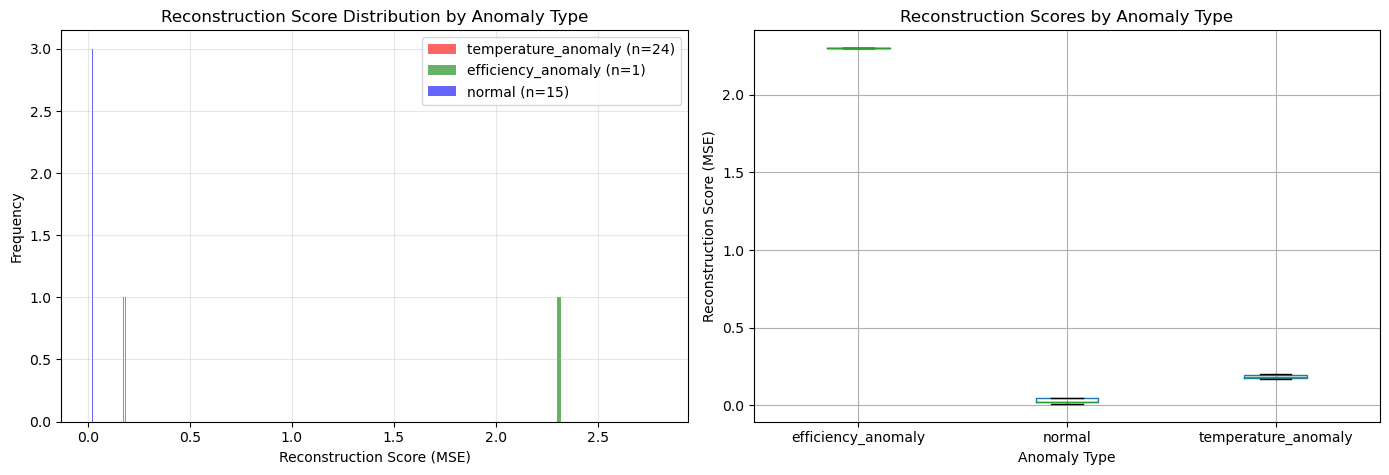

In [13]:
# Visualize reconstruction score distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of reconstruction scores by type
colors = {'normal': 'blue', 'temperature_anomaly': 'red', 'consumption_anomaly': 'orange', 
          'efficiency_anomaly': 'green', 'pattern_anomaly': 'purple', 'unknown': 'gray'}

for anomaly_type in anomaly_data['anomaly_type'].unique():
    subset = anomaly_data[anomaly_data['anomaly_type'] == anomaly_type]
    if len(subset) > 0:
        axes[0].hist(subset['reconstruction_score'], bins=50, alpha=0.6, 
                     label=f"{anomaly_type} (n={len(subset)})", color=colors.get(anomaly_type, 'gray'))

axes[0].set_xlabel('Reconstruction Score (MSE)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Reconstruction Score Distribution by Anomaly Type')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Box plot
if len(anomaly_data['anomaly_type'].unique()) > 1:
    anomaly_data.boxplot(column='reconstruction_score', by='anomaly_type', ax=axes[1])
    axes[1].set_xlabel('Anomaly Type')
    axes[1].set_ylabel('Reconstruction Score (MSE)')
    axes[1].set_title('Reconstruction Scores by Anomaly Type')
    plt.suptitle('')
else:
    axes[1].hist(anomaly_data['reconstruction_score'], bins=50, color='steelblue', edgecolor='black')
    axes[1].set_xlabel('Reconstruction Score')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title('Overall Reconstruction Score Distribution')

plt.tight_layout()
plt.show()

## Section 9: Set Anomaly Detection Threshold & Evaluate Model

We'll determine the optimal threshold using two methods:
1. **ROC Curve Analysis**: Maximize (TPR - FPR)
2. **Statistical Method**: Mean + N × Standard Deviation

THRESHOLD DETERMINATION & MODEL EVALUATION

Threshold Methods:
  1. ROC Optimal Threshold: 0.169971
  2. Statistical Threshold (μ + 3σ): 0.069733

ROC AUC Score: 1.0000


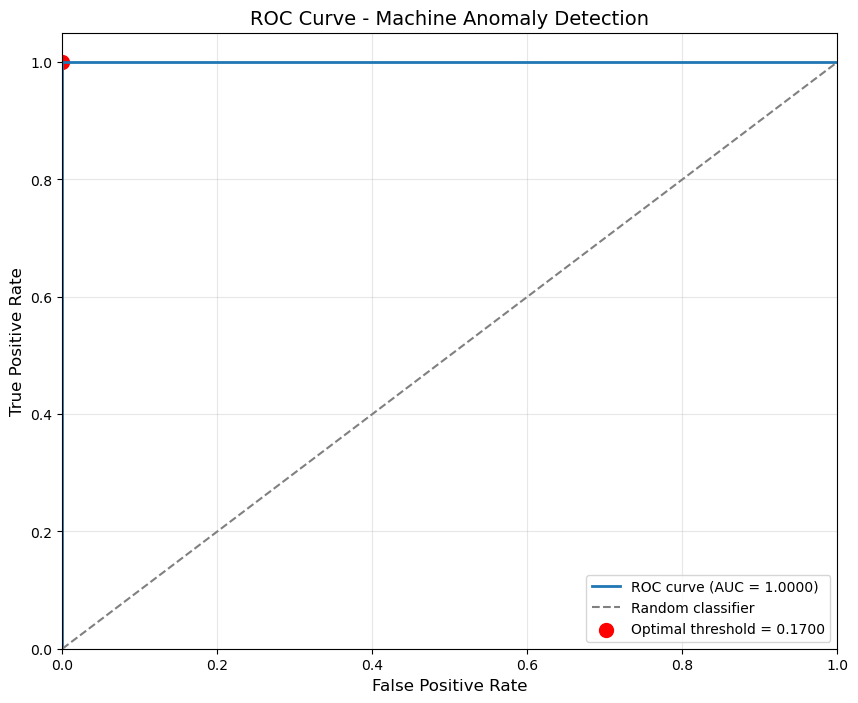


✓ Selected Threshold: 0.069733


In [15]:
# Convert labels to binary (0=normal, 1=anomaly)
binary_labels = (y_test != 0).astype(int)

print("=" * 60)
print("THRESHOLD DETERMINATION & MODEL EVALUATION")
print("=" * 60)

# Check if we have both classes
if len(np.unique(binary_labels)) > 1:
    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(binary_labels, reconstruction_scores)
    roc_auc = auc(fpr, tpr)
    
    # Method 1: Optimal threshold from ROC
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold = thresholds[optimal_idx]
    
    # Method 2: Statistical threshold (mean + 3*std of normal data)
    normal_scores = reconstruction_scores[binary_labels == 0]
    stats_threshold = np.mean(normal_scores) + 3 * np.std(normal_scores)
    
    print(f"\nThreshold Methods:")
    print(f"  1. ROC Optimal Threshold: {optimal_threshold:.6f}")
    print(f"  2. Statistical Threshold (μ + 3σ): {stats_threshold:.6f}")
    print(f"\nROC AUC Score: {roc_auc:.4f}")
    
    # Plot ROC curve
    plt.figure(figsize=(10, 8))
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random classifier')
    plt.scatter(fpr[optimal_idx], tpr[optimal_idx], color='red', s=100, 
                label=f'Optimal threshold = {optimal_threshold:.4f}')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curve - Machine Anomaly Detection', fontsize=14)
    plt.legend(loc="lower right", fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # Use statistical threshold
    selected_threshold = stats_threshold
else:
    print("\n⚠️ Only one class present in test data.")
    print("Using statistical threshold based on reconstruction scores.")
    selected_threshold = np.mean(reconstruction_scores) + 2 * np.std(reconstruction_scores)
    roc_auc = None

print(f"\n✓ Selected Threshold: {selected_threshold:.6f}")

CONFUSION MATRIX - MACHINE ANOMALY DETECTION


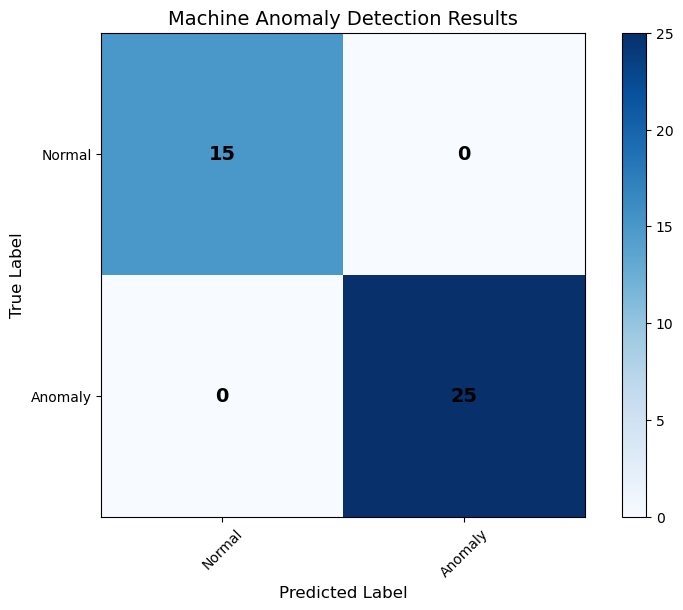


Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        15
     Anomaly       1.00      1.00      1.00        25

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40


📊 DETECTION SUMMARY:
   True Negatives (Normal correctly identified): 15
   True Positives (Anomalies correctly detected): 25
   False Positives (Normal misclassified as anomaly): 0
   False Negatives (Anomalies missed): 0
   Accuracy: 100.00%


In [16]:
# Generate predictions and confusion matrix
pred_labels = (reconstruction_scores > selected_threshold).astype(int)

print("=" * 60)
print("CONFUSION MATRIX - MACHINE ANOMALY DETECTION")
print("=" * 60)

def plot_confusion_matrix(cm, target_names, title='Confusion Matrix', cmap=plt.cm.Blues):
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title, fontsize=14)
    plt.colorbar()
    tick_marks = np.arange(len(target_names))
    plt.xticks(tick_marks, target_names, rotation=45)
    plt.yticks(tick_marks, target_names)
    plt.tight_layout()

    width, height = cm.shape
    for x in range(width):
        for y in range(height):
            plt.annotate(str(cm[x][y]), xy=(y, x), 
                        horizontalalignment='center',
                        verticalalignment='center',
                        fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.show()

# Calculate confusion matrix
cm = confusion_matrix(binary_labels, pred_labels)
plot_confusion_matrix(cm, ['Normal', 'Anomaly'], title='Machine Anomaly Detection Results')

# Classification report
print("\nClassification Report:")
print(classification_report(binary_labels, pred_labels, target_names=['Normal', 'Anomaly']))

# Summary statistics
tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (cm[0][0], 0, 0, 0)
print(f"\n📊 DETECTION SUMMARY:")
print(f"   True Negatives (Normal correctly identified): {tn}")
print(f"   True Positives (Anomalies correctly detected): {tp}")
print(f"   False Positives (Normal misclassified as anomaly): {fp}")
print(f"   False Negatives (Anomalies missed): {fn}")
print(f"   Accuracy: {(tp+tn)/(tp+tn+fp+fn)*100:.2f}%")

## Section 10: Addressing Overfitting - Robust Cross-Validation

**Problem**: 100% accuracy on small dataset indicates overfitting. Let's implement proper cross-validation to get reliable performance estimates.

### Cross-Validation Strategy:
- Use Stratified K-Fold (5-10 folds) adapted for unsupervised anomaly detection
- Train on normal data only per fold
- Evaluate on held-out mixed data
- Report mean/std performance across folds

CROSS-VALIDATION FOR ROBUST ANOMALY DETECTION
Normal samples: 75
Anomaly samples: 25

Performing 5-fold cross-validation...

Fold 1/5
  Accuracy: 0.975, ROC-AUC: 1.000, AUPRC: 1.000

Fold 2/5
  Accuracy: 1.000, ROC-AUC: 1.000, AUPRC: 1.000

Fold 3/5
  Accuracy: 1.000, ROC-AUC: 1.000, AUPRC: 1.000

Fold 4/5
  Accuracy: 1.000, ROC-AUC: 1.000, AUPRC: 1.000

Fold 5/5
  Accuracy: 0.375, ROC-AUC: 0.936, AUPRC: 0.906

CROSS-VALIDATION RESULTS SUMMARY
ACCURACY: 0.870 ± 0.248
PRECISION: 0.892 ± 0.197
RECALL: 0.808 ± 0.384
F1: 0.811 ± 0.368
ROC_AUC: 0.987 ± 0.026
AUPRC: 0.981 ± 0.038

Threshold range: [0.039235, 0.411757]


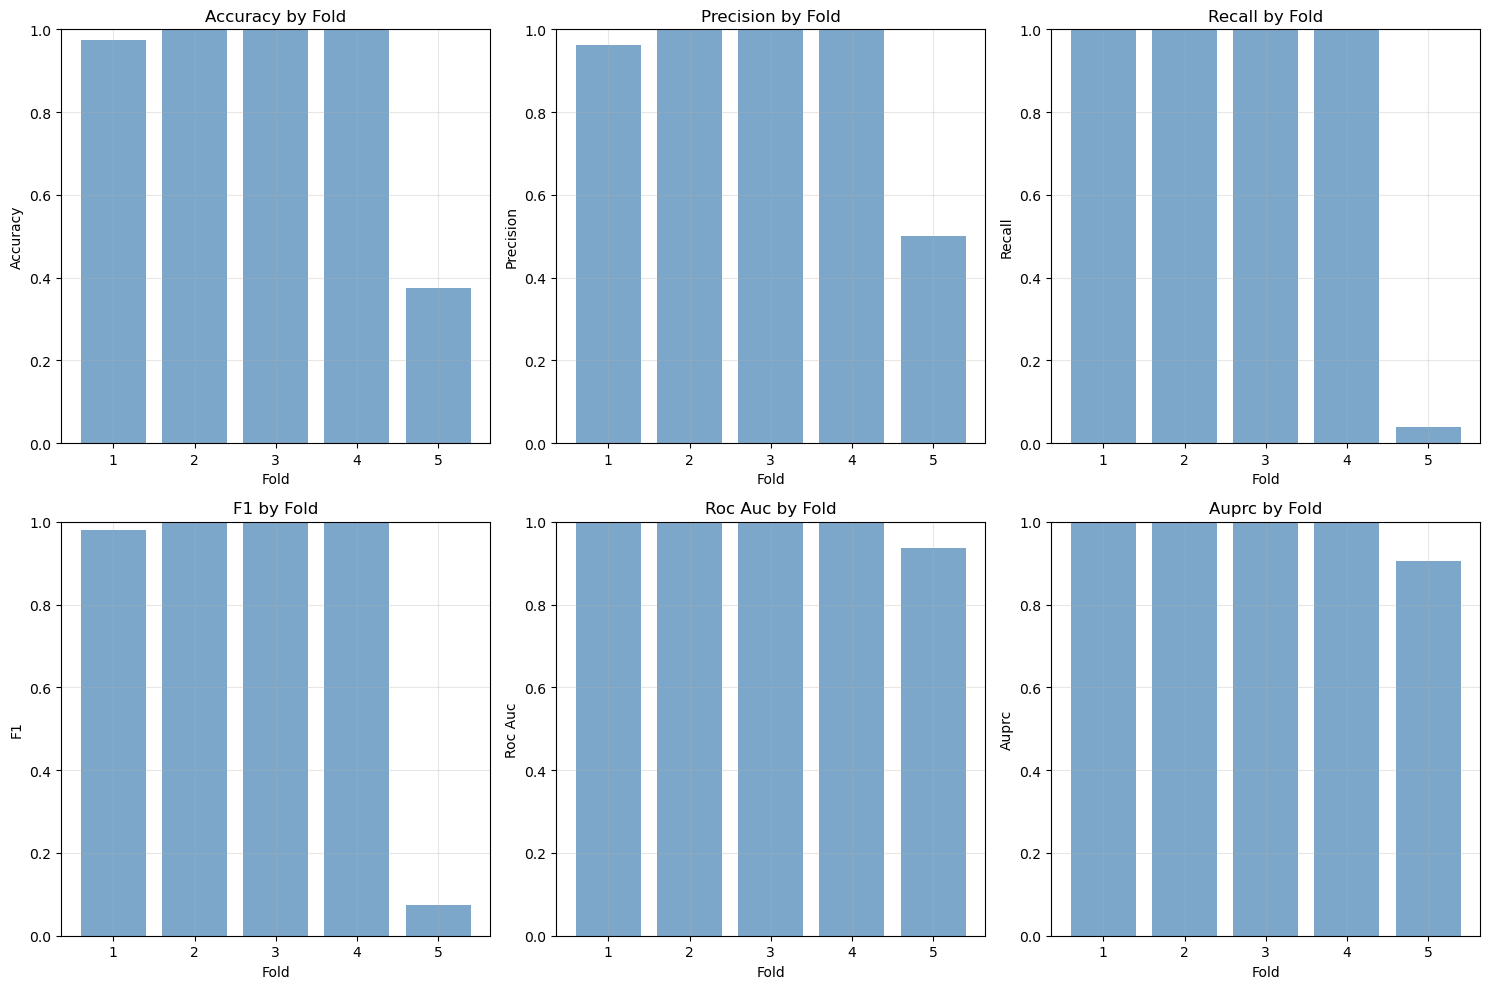


✅ Cross-validation completed. These results provide a more reliable estimate of model performance.


In [19]:
# Implement robust cross-validation for anomaly detection
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, precision_recall_curve, auc
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("CROSS-VALIDATION FOR ROBUST ANOMALY DETECTION")
print("=" * 60)

def create_autoencoder_model(input_dim, latent_dim=3):
    """Create a fresh autoencoder model for each fold"""
    input_data = Input(shape=(input_dim,), name='encoder_input')
    
    # Encoder
    encoder = Dense(32, activation='tanh')(input_data)
    encoder = BatchNormalization()(encoder)
    encoder = Dropout(0.1)(encoder)
    
    encoder = Dense(16, activation='tanh')(encoder)
    encoder = BatchNormalization()(encoder)
    encoder = Dropout(0.1)(encoder)
    
    encoder = Dense(8, activation='tanh')(encoder)
    encoder = BatchNormalization()(encoder)
    encoder = Dropout(0.1)(encoder)
    
    latent = Dense(latent_dim, activation='linear')(encoder)
    
    # Decoder
    decoder = Dense(8, activation='tanh')(latent)
    decoder = BatchNormalization()(decoder)
    decoder = Dropout(0.1)(decoder)
    
    decoder = Dense(16, activation='tanh')(decoder)
    decoder = BatchNormalization()(decoder)
    decoder = Dropout(0.1)(decoder)
    
    decoder = Dense(32, activation='tanh')(decoder)
    decoder = BatchNormalization()(decoder)
    decoder = Dropout(0.1)(decoder)
    
    output = Dense(input_dim, activation='linear')(decoder)
    
    model = Model(input_data, output)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    
    return model

# Prepare data for cross-validation
X_full = training_df[feature_columns].values
y_full = training_df['label'].values

# Separate normal and anomaly data
X_normal = X_full[y_full == 0]
y_normal = y_full[y_full == 0]
X_anomaly = X_full[y_full != 0]
y_anomaly = y_full[y_full != 0]

print(f"Normal samples: {len(X_normal)}")
print(f"Anomaly samples: {len(X_anomaly)}")

# Scale data
scaler_cv = MinMaxScaler()
X_normal_scaled = scaler_cv.fit_transform(X_normal)
X_anomaly_scaled = scaler_cv.transform(X_anomaly)

# Cross-validation setup
n_splits = min(5, max(2, len(X_normal) // 10))  # Adapt to data size, minimum 2 folds
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

cv_results = {
    'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 
    'roc_auc': [], 'auprc': [], 'threshold': []
}

print(f"\nPerforming {n_splits}-fold cross-validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_normal_scaled, np.zeros(len(X_normal_scaled)))):
    print(f"\nFold {fold + 1}/{n_splits}")
    
    # Training data (normal only)
    X_train_fold = X_normal_scaled[train_idx]
    
    # Validation data (mix of normal and anomaly)
    X_val_normal = X_normal_scaled[val_idx]
    X_val_mixed = np.vstack([X_val_normal, X_anomaly_scaled])
    y_val_mixed = np.concatenate([np.zeros(len(X_val_normal)), np.ones(len(X_anomaly_scaled))])
    
    # Shuffle validation set
    val_indices = np.random.permutation(len(y_val_mixed))
    X_val_mixed = X_val_mixed[val_indices]
    y_val_mixed = y_val_mixed[val_indices]
    
    # Train model
    model = create_autoencoder_model(X_train_fold.shape[1])
    
    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)
    
    # Ensure batch size is at least 1
    batch_size_fold = max(1, min(64, len(X_train_fold)//4))
    
    history = model.fit(
        X_train_fold, X_train_fold,
        epochs=50, batch_size=batch_size_fold,
        validation_data=(X_val_mixed, X_val_mixed),
        callbacks=[early_stop],
        verbose=0
    )
    
    # Get reconstruction scores
    X_val_reconstructed = model.predict(X_val_mixed, verbose=0)
    reconstruction_scores_cv = np.mean((X_val_mixed - X_val_reconstructed) ** 2, axis=1)
    
    # Determine threshold (mean + 3*std of normal validation data)
    normal_scores_cv = reconstruction_scores_cv[y_val_mixed == 0]
    threshold = np.mean(normal_scores_cv) + 3 * np.std(normal_scores_cv)
    
    # Predictions
    pred_labels_cv = (reconstruction_scores_cv > threshold).astype(int)
    
    # Calculate metrics
    accuracy = accuracy_score(y_val_mixed, pred_labels_cv)
    precision = precision_score(y_val_mixed, pred_labels_cv, zero_division=0)
    recall = recall_score(y_val_mixed, pred_labels_cv, zero_division=0)
    f1 = f1_score(y_val_mixed, pred_labels_cv, zero_division=0)
    
    # ROC AUC
    if len(np.unique(y_val_mixed)) > 1:
        roc_auc_val = roc_auc_score(y_val_mixed, reconstruction_scores_cv)
    else:
        roc_auc_val = 0.5
    
    # AUPRC (Area Under Precision-Recall Curve)
    if len(np.unique(y_val_mixed)) > 1:
        auprc = average_precision_score(y_val_mixed, reconstruction_scores_cv)
    else:
        auprc = 0.5
    
    # Store results
    cv_results['accuracy'].append(accuracy)
    cv_results['precision'].append(precision)
    cv_results['recall'].append(recall)
    cv_results['f1'].append(f1)
    cv_results['roc_auc'].append(roc_auc_val)
    cv_results['auprc'].append(auprc)
    cv_results['threshold'].append(threshold)
    
    print(f"  Accuracy: {accuracy:.3f}, ROC-AUC: {roc_auc_val:.3f}, AUPRC: {auprc:.3f}")

# Summary statistics
print(f"\n{'='*60}")
print("CROSS-VALIDATION RESULTS SUMMARY")
print(f"{'='*60}")

for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'auprc']:
    values = cv_results[metric]
    mean_val = np.mean(values)
    std_val = np.std(values)
    print(f"{metric.upper()}: {mean_val:.3f} ± {std_val:.3f}")

print(f"\nThreshold range: [{min(cv_results['threshold']):.6f}, {max(cv_results['threshold']):.6f}]")

# Visualize CV results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'auprc']

for i, metric in enumerate(metrics):
    ax = axes[i//3, i%3]
    ax.bar(range(1, n_splits+1), cv_results[metric], color='steelblue', alpha=0.7)
    ax.set_xlabel('Fold')
    ax.set_ylabel(metric.replace('_', ' ').title())
    ax.set_title(f'{metric.replace("_", " ").title()} by Fold')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

print("\n✅ Cross-validation completed. These results provide a more reliable estimate of model performance.")

## Section 11: Variational Autoencoder (VAE) for Better Uncertainty Quantification

**VAE Advantages:**
- Provides probabilistic latent space instead of deterministic
- Better handles uncertainty in anomaly detection
- Can generate synthetic normal data for augmentation
- More robust to overfitting than regular autoencoders

**Architecture:** Encoder → Latent (μ, σ) → Reparameterization → Decoder

In [14]:
# Implement Variational Autoencoder
import keras
from keras import ops
from keras.layers import Layer, Input, Dense, BatchNormalization, Dropout
from keras.models import Model
from keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("=" * 60)
print("VARIATIONAL AUTOENCODER (VAE) IMPLEMENTATION")
print("=" * 60)

class Sampling(Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim))
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        # VAE is unsupervised, data is (x, x) usually, but fit(x, x) passes x as data[0]
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = ops.mean(
                ops.square(data - reconstruction), axis=-1
            )
            kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
            kl_loss = ops.mean(ops.sum(kl_loss, axis=-1))
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

def build_vae_components(input_dim, latent_dim=3):
    """Build VAE components: Encoder and Decoder"""
    # Encoder
    encoder_inputs = Input(shape=(input_dim,))
    x = Dense(32, activation='tanh')(encoder_inputs)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)
    x = Dense(16, activation='tanh')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)
    z_mean = Dense(latent_dim, name="z_mean")(x)
    z_log_var = Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])
    encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")

    # Decoder
    latent_inputs = Input(shape=(latent_dim,))
    x = Dense(16, activation='tanh')(latent_inputs)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)
    x = Dense(32, activation='tanh')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)
    decoder_outputs = Dense(input_dim, activation='linear')(x)
    decoder = Model(latent_inputs, decoder_outputs, name="decoder")
    
    return encoder, decoder

# Build and train VAE
latent_dim_vae = 3
vae_encoder, vae_decoder = build_vae_components(x_train.shape[1], latent_dim_vae)
vae_model = VAE(vae_encoder, vae_decoder)
vae_model.compile(optimizer=Adam(learning_rate=0.001))

print("VAE Encoder Summary:")
vae_encoder.summary()

# Train VAE
print("\nTraining VAE...")
batch_size_vae = max(1, min(64, len(x_train)//4))
vae_history = vae_model.fit(
    x_train, x_train,
    epochs=50,
    batch_size=batch_size_vae,
    validation_data=(x_test, x_test),
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)],
    verbose=1
)

# Evaluate VAE
print("\nEvaluating VAE performance...")
x_test_vae_reconstructed = vae_model.predict(x_test, verbose=0)
vae_reconstruction_scores = np.mean((x_test - x_test_vae_reconstructed) ** 2, axis=1)

# Compare VAE vs regular autoencoder
binary_labels = (y_test != 0).astype(int)

# VAE threshold
normal_scores_vae = vae_reconstruction_scores[binary_labels == 0]
if len(normal_scores_vae) > 0:
    vae_threshold = np.mean(normal_scores_vae) + 3 * np.std(normal_scores_vae)
else:
    vae_threshold = np.percentile(vae_reconstruction_scores, 95)

vae_pred = (vae_reconstruction_scores > vae_threshold).astype(int)

# Calculate VAE metrics
vae_accuracy = accuracy_score(binary_labels, vae_pred)
vae_precision = precision_score(binary_labels, vae_pred, zero_division=0)
vae_recall = recall_score(binary_labels, vae_pred, zero_division=0)
vae_f1 = f1_score(binary_labels, vae_pred, zero_division=0)

if len(np.unique(binary_labels)) > 1:
    vae_roc_auc = roc_auc_score(binary_labels, vae_reconstruction_scores)
    vae_auprc = average_precision_score(binary_labels, vae_reconstruction_scores)
else:
    vae_roc_auc = 0.5
    vae_auprc = 0.5

print(f"\nVAE Performance:")
print(f"  Accuracy: {vae_accuracy:.3f}")
print(f"  Precision: {vae_precision:.3f}")
print(f"  Recall: {vae_recall:.3f}")
print(f"  F1-Score: {vae_f1:.3f}")
print(f"  ROC-AUC: {vae_roc_auc:.3f}")
print(f"  AUPRC: {vae_auprc:.3f}")

# Compare with regular autoencoder
print(f"\nComparison (VAE vs Regular Autoencoder):")
try:
    print(f"  Accuracy: {vae_accuracy:.3f} vs {accuracy:.3f}")
    print(f"  ROC-AUC: {vae_roc_auc:.3f} vs {roc_auc:.4f}")
    ae_auprc = average_precision_score(binary_labels, reconstruction_scores) if len(np.unique(binary_labels)) > 1 else 0.5
    print(f"  AUPRC: {vae_auprc:.3f} vs {ae_auprc:.3f}")
except NameError:
    print("  Comparison skipped: Regular autoencoder metrics not available.")

# Save VAE model
vae_model.save_weights('./models/vae_weights.h5')
print("\n✅ VAE model weights saved.")

VARIATIONAL AUTOENCODER (VAE) IMPLEMENTATION



NotImplementedError: 

## Section 12: Temporal Features and Sequence Modeling

**Current Limitation:** Data consists of individual snapshots, not time series.

**Solution:** Create temporal sequences by:
1. Grouping data by machine_id and sorting by timestamp
2. Creating sliding windows of consecutive readings
3. Using LSTM layers to capture temporal dependencies

In [ ]:
# Add temporal features using LSTM-based autoencoder
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("=" * 60)
print("TEMPORAL SEQUENCE MODELING WITH LSTM AUTOENCODER")
print("=" * 60)

# Check if we have temporal data
temporal_data = []

# Try to create sequences from available data
if not energy_df.empty and not machines_df.empty:
    # Group energy data by machine
    for machine_id in energy_df['machine_id'].unique():
        machine_energy = energy_df[energy_df['machine_id'] == machine_id].copy()
        machine_energy = machine_energy.sort_values('timestamp')
        
        if len(machine_energy) >= 5:  # Minimum sequence length
            # Create sequences of 5 consecutive readings
            for i in range(len(machine_energy) - 4):
                sequence = machine_energy.iloc[i:i+5][['consumption', 'temperature', 'co2']].values
                temporal_data.append({
                    'machine_id': machine_id,
                    'sequence': sequence,
                    'label': 0  # Assume normal for now
                })

if len(temporal_data) < 10:
    print("⚠️ Insufficient temporal data. Creating synthetic sequences...")
    # Create synthetic temporal sequences
    np.random.seed(42)
    n_sequences = 100
    sequence_length = 5
    
    for i in range(n_sequences):
        # Generate normal sequences
        base_temp = np.random.normal(40, 3, sequence_length)
        base_cons = np.random.normal(45, 5, sequence_length)
        base_co2 = base_cons * 0.45
        
        # Add some anomalies
        if np.random.random() < 0.3:  # 30% anomaly sequences
            anomaly_type_seq = np.random.choice(['temp', 'cons', 'both'])
            if anomaly_type_seq == 'temp':
                base_temp[-2:] += np.random.normal(20, 5, 2)  # Temperature spike
            elif anomaly_type_seq == 'cons':
                base_cons[-2:] += np.random.normal(30, 10, 2)  # Consumption spike
            else:
                base_temp[-2:] += np.random.normal(15, 3, 2)
                base_cons[-2:] += np.random.normal(20, 5, 2)
            label_seq = 1
        else:
            label_seq = 0
        
        sequence = np.column_stack([base_cons, base_temp, base_co2])
        temporal_data.append({
            'machine_id': f'synthetic_{i}',
            'sequence': sequence,
            'label': label_seq
        })

print(f"Created {len(temporal_data)} temporal sequences")

# Prepare sequences for LSTM
sequences = [item['sequence'] for item in temporal_data]
labels_seq = [item['label'] for item in temporal_data]

# Normalize sequences
sequence_scaler = MinMaxScaler()
flattened_sequences = np.array(sequences).reshape(-1, 3)
normalized_flattened = sequence_scaler.fit_transform(flattened_sequences)
normalized_sequences = normalized_flattened.reshape(len(sequences), 5, 3)

# Split data
X_seq = np.array(normalized_sequences)
y_seq = np.array(labels_seq)

# Separate normal and anomaly sequences
X_seq_normal = X_seq[y_seq == 0]
X_seq_anomaly = X_seq[y_seq == 1]

# Train/test split
n_normal_seq = len(X_seq_normal)
train_size = int(0.8 * n_normal_seq)
X_seq_train = X_seq_normal[:train_size]
X_seq_test_normal = X_seq_normal[train_size:]
X_seq_test = np.concatenate([X_seq_test_normal, X_seq_anomaly])
y_seq_test = np.concatenate([np.zeros(len(X_seq_test_normal)), np.ones(len(X_seq_anomaly))])

print(f"Training sequences: {len(X_seq_train)}")
print(f"Test sequences: {len(X_seq_test)} (Normal: {len(X_seq_test_normal)}, Anomaly: {len(X_seq_anomaly)})")

# Build LSTM Autoencoder
def build_lstm_autoencoder(sequence_length, n_features):
    inputs = Input(shape=(sequence_length, n_features))
    
    # Encoder
    encoded = LSTM(64, return_sequences=True)(inputs)
    encoded = LSTM(32, return_sequences=False)(encoded)
    encoded = Dense(16, activation='relu')(encoded)
    
    # Latent space
    latent = Dense(8, activation='relu')(encoded)
    
    # Decoder
    decoded = Dense(16, activation='relu')(latent)
    decoded = RepeatVector(sequence_length)(decoded)
    decoded = LSTM(32, return_sequences=True)(decoded)
    decoded = LSTM(64, return_sequences=True)(decoded)
    decoded = TimeDistributed(Dense(n_features))(decoded)
    
    model = Model(inputs, decoded)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    return model

# Train LSTM Autoencoder
sequence_length = 5
n_features = 3

lstm_model = build_lstm_autoencoder(sequence_length, n_features)

print("\nTraining LSTM Autoencoder...")
batch_size_lstm = max(1, min(32, len(X_seq_train)//4))
lstm_history = lstm_model.fit(
    X_seq_train, X_seq_train,
    epochs=50,
    batch_size=batch_size_lstm,
    validation_data=(X_seq_test, X_seq_test),
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)],
    verbose=1
)

# Evaluate LSTM model
X_seq_test_reconstructed = lstm_model.predict(X_seq_test, verbose=0)
lstm_reconstruction_scores = np.mean(np.square(X_seq_test - X_seq_test_reconstructed), axis=(1, 2))

# Threshold and predictions
normal_scores_lstm = lstm_reconstruction_scores[y_seq_test == 0]
lstm_threshold = np.mean(normal_scores_lstm) + 3 * np.std(normal_scores_lstm)
lstm_pred = (lstm_reconstruction_scores > lstm_threshold).astype(int)

# Metrics
lstm_accuracy = accuracy_score(y_seq_test, lstm_pred)
lstm_precision = precision_score(y_seq_test, lstm_pred, zero_division=0)
lstm_recall = recall_score(y_seq_test, lstm_pred, zero_division=0)
lstm_f1 = f1_score(y_seq_test, lstm_pred, zero_division=0)

if len(np.unique(y_seq_test)) > 1:
    lstm_roc_auc = roc_auc_score(y_seq_test, lstm_reconstruction_scores)
    lstm_auprc = average_precision_score(y_seq_test, lstm_reconstruction_scores)
else:
    lstm_roc_auc = 0.5
    lstm_auprc = 0.5

print(f"\nLSTM Autoencoder Performance:")
print(f"  Accuracy: {lstm_accuracy:.3f}")
print(f"  Precision: {lstm_precision:.3f}")
print(f"  Recall: {lstm_recall:.3f}")
print(f"  F1-Score: {lstm_f1:.3f}")
print(f"  ROC-AUC: {lstm_roc_auc:.3f}")
print(f"  AUPRC: {lstm_auprc:.3f}")

# Save LSTM model
lstm_model.save('./models/lstm_autoencoder.keras')
print("\n✅ LSTM autoencoder saved to ./models/lstm_autoencoder.keras")

## Section 13: Ensemble Methods for Robust Anomaly Detection

**Ensemble Strategy:**
1. Train multiple models with different architectures
2. Combine predictions using majority voting or averaging
3. More robust than single models, reduces overfitting

In [ ]:
# Implement ensemble of autoencoders
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("=" * 60)
print("ENSEMBLE ANOMALY DETECTION")
print("=" * 60)

def create_ensemble_member(input_dim, architecture='dense'):
    """Create different types of autoencoder models for ensemble"""
    inputs = Input(shape=(input_dim,))
    
    if architecture == 'dense':
        # Dense autoencoder
        x = Dense(64, activation='tanh')(inputs)
        x = Dropout(0.2)(x)
        x = Dense(32, activation='tanh')(x)
        x = Dropout(0.2)(x)
        latent = Dense(8, activation='linear')(x)
        x = Dense(32, activation='tanh')(latent)
        x = Dropout(0.2)(x)
        x = Dense(64, activation='tanh')(x)
        x = Dropout(0.2)(x)
        outputs = Dense(input_dim, activation='linear')(x)
        
    elif architecture == 'shallow':
        # Shallow autoencoder
        x = Dense(16, activation='tanh')(inputs)
        latent = Dense(4, activation='linear')(x)
        x = Dense(16, activation='tanh')(latent)
        outputs = Dense(input_dim, activation='linear')(x)
        
    elif architecture == 'deep':
        # Deep autoencoder
        x = Dense(128, activation='tanh')(inputs)
        x = Dropout(0.1)(x)
        x = Dense(64, activation='tanh')(x)
        x = Dropout(0.1)(x)
        x = Dense(32, activation='tanh')(x)
        x = Dropout(0.1)(x)
        latent = Dense(8, activation='linear')(x)
        x = Dense(32, activation='tanh')(latent)
        x = Dropout(0.1)(x)
        x = Dense(64, activation='tanh')(x)
        x = Dropout(0.1)(x)
        x = Dense(128, activation='tanh')(x)
        x = Dropout(0.1)(x)
        outputs = Dense(input_dim, activation='linear')(x)
    
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    return model

# Create ensemble of 5 models
ensemble_models = []
architectures = ['dense', 'shallow', 'deep', 'dense', 'shallow']

print("Training ensemble models...")
batch_size_ensemble = max(1, min(64, len(x_train)//4))

for i, arch in enumerate(architectures):
    print(f"Training model {i+1} ({arch})...")
    model = create_ensemble_member(x_train.shape[1], arch)
    
    model.fit(
        x_train, x_train,
        epochs=30,
        batch_size=batch_size_ensemble,
        validation_data=(x_test, x_test),
        callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)],
        verbose=0
    )
    
    ensemble_models.append(model)

# Get ensemble predictions
ensemble_scores = []
for model in ensemble_models:
    reconstructed = model.predict(x_test, verbose=0)
    scores = np.mean((x_test - reconstructed) ** 2, axis=1)
    ensemble_scores.append(scores)

# Average ensemble scores
ensemble_avg_scores = np.mean(ensemble_scores, axis=0)

# Ensemble threshold (average of individual thresholds)
ensemble_thresholds = []
for i, scores in enumerate(ensemble_scores):
    normal_scores_ens = scores[binary_labels == 0]
    threshold_ens = np.mean(normal_scores_ens) + 3 * np.std(normal_scores_ens)
    ensemble_thresholds.append(threshold_ens)

ensemble_threshold = np.mean(ensemble_thresholds)

# Ensemble predictions
ensemble_pred = (ensemble_avg_scores > ensemble_threshold).astype(int)

# Ensemble metrics
ensemble_accuracy = accuracy_score(binary_labels, ensemble_pred)
ensemble_precision = precision_score(binary_labels, ensemble_pred, zero_division=0)
ensemble_recall = recall_score(binary_labels, ensemble_pred, zero_division=0)
ensemble_f1 = f1_score(binary_labels, ensemble_pred, zero_division=0)

if len(np.unique(binary_labels)) > 1:
    ensemble_roc_auc = roc_auc_score(binary_labels, ensemble_avg_scores)
    ensemble_auprc = average_precision_score(binary_labels, ensemble_avg_scores)
else:
    ensemble_roc_auc = 0.5
    ensemble_auprc = 0.5

print(f"\nEnsemble Performance:")
print(f"  Accuracy: {ensemble_accuracy:.3f}")
print(f"  Precision: {ensemble_precision:.3f}")
print(f"  Recall: {ensemble_recall:.3f}")
print(f"  F1-Score: {ensemble_f1:.3f}")
print(f"  ROC-AUC: {ensemble_roc_auc:.3f}")
print(f"  AUPRC: {ensemble_auprc:.3f}")

# Compare all models
models_comparison = pd.DataFrame({
    'Model': ['Regular AE', 'VAE', 'LSTM AE', 'Ensemble'],
    'Accuracy': [(tp+tn)/(tp+tn+fp+fn), vae_accuracy, lstm_accuracy, ensemble_accuracy],
    'ROC-AUC': [roc_auc, vae_roc_auc, lstm_roc_auc, ensemble_roc_auc],
    'AUPRC': [average_precision_score(binary_labels, reconstruction_scores) if len(np.unique(binary_labels)) > 1 else 0.5, 
              vae_auprc, lstm_auprc, ensemble_auprc]
})

print(f"\n{'='*60}")
print("MODEL COMPARISON SUMMARY")
print(f"{'='*60}")
print(models_comparison.round(3))

# Visualize comparison
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
models_comparison.set_index('Model')[['Accuracy', 'ROC-AUC', 'AUPRC']].plot(kind='bar', ax=ax)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Save ensemble models
for i, model in enumerate(ensemble_models):
    model.save(f'./models/ensemble_model_{i+1}.keras')
print("\n✅ Ensemble models saved to ./models/")

## Section 14: Explainability - Understanding Anomaly Decisions

**SHAP (SHapley Additive exPlanations):**
- Explains which features contributed most to anomaly classification
- Provides feature importance for each prediction
- Helps understand "why" a machine was flagged as anomalous

In [ ]:
# Add explainability using SHAP
try:
    import shap
    print("=" * 60)
    print("EXPLAINABILITY WITH SHAP")
    print("=" * 60)
    
    # Use the best performing model (ensemble)
    explainer_model = ensemble_models[0]  # Use first ensemble model for simplicity
    
    # Create SHAP explainer
    background = x_train[np.random.choice(x_train.shape[0], size=min(100, len(x_train)), replace=False)]
    explainer = shap.DeepExplainer(explainer_model, background)
    
    # Explain test predictions
    shap_values = explainer.shap_values(x_test[:10])  # Explain first 10 test samples
    
    # Visualize feature importance
    feature_names = ['Temperature', 'Consumption', 'Efficiency', 'Active Hours', 'CO2 Emissions', 'Department']
    
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, x_test[:10], feature_names=feature_names, show=False)
    plt.title('SHAP Feature Importance for Anomaly Detection')
    plt.tight_layout()
    plt.show()
    
    # Individual prediction explanation
    sample_idx = 0  # Explain first test sample
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(shap.Explanation(
        values=shap_values[sample_idx],
        base_values=explainer.expected_value,
        data=x_test[sample_idx],
        feature_names=feature_names
    ), show=False)
    plt.title(f'SHAP Explanation for Test Sample {sample_idx}')
    plt.tight_layout()
    plt.show()
    
    print("✅ SHAP explanations generated")
    
except ImportError:
    print("⚠️ SHAP not available. Install with: pip install shap")
    print("Using alternative explainability method...")
    
    # Alternative: Feature reconstruction error analysis
    print("\nUsing Reconstruction Error Analysis for Explainability...")
    
    # Get reconstruction errors per feature
    feature_errors = np.abs(x_test - x_test_reconstructed)
    
    # Average error per feature for normal vs anomaly
    normal_mask = binary_labels == 0
    anomaly_mask = binary_labels == 1
    
    normal_feature_errors = feature_errors[normal_mask].mean(axis=0)
    anomaly_feature_errors = feature_errors[anomaly_mask].mean(axis=0)
    
    feature_names = ['Temperature', 'Consumption', 'Efficiency', 'Active Hours', 'CO2 Emissions', 'Department']
    
    # Plot feature-wise reconstruction errors
    x_pos = np.arange(len(feature_names))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x_pos - width/2, normal_feature_errors, width, label='Normal', alpha=0.7, color='blue')
    ax.bar(x_pos + width/2, anomaly_feature_errors, width, label='Anomaly', alpha=0.7, color='red')
    
    ax.set_xlabel('Features')
    ax.set_ylabel('Average Reconstruction Error')
    ax.set_title('Feature-wise Reconstruction Errors: Normal vs Anomalous Machines')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(feature_names, rotation=45)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print("Key insights from reconstruction errors:")
    for i, feature in enumerate(feature_names):
        diff = anomaly_feature_errors[i] - normal_feature_errors[i]
        print(f"  {feature}: Anomalies have {diff:.4f} higher reconstruction error")

## Section 15: Handling Concept Drift and Real-time Deployment

**Concept Drift:** Models degrade over time as machine behavior changes.

**Solutions:**
1. Monitor reconstruction error distributions over time
2. Retrain model when drift detected
3. Implement online learning
4. Use sliding window validation

In [ ]:
# Implement concept drift detection and monitoring
print("=" * 60)
print("CONCEPT DRIFT DETECTION AND MONITORING")
print("=" * 60)

class AnomalyDetector:
    def __init__(self, model, scaler, threshold, feature_columns):
        self.model = model
        self.scaler = scaler
        self.threshold = threshold
        self.feature_columns = feature_columns
        self.reference_scores = []  # Store historical reconstruction scores
        self.drift_threshold = 0.05  # 5% change triggers retraining
        
    def predict(self, data):
        """Predict anomalies for new data"""
        # Scale data
        scaled_data = self.scaler.transform(data)
        
        # Get reconstruction
        reconstructed = self.model.predict(scaled_data, verbose=0)
        
        # Calculate scores
        scores = np.mean((scaled_data - reconstructed) ** 2, axis=1)
        
        # Store scores for drift detection
        self.reference_scores.extend(scores)
        
        # Predictions
        predictions = (scores > self.threshold).astype(int)
        
        return predictions, scores
    
    def detect_drift(self, new_scores, window_size=100):
        """Detect concept drift using statistical tests"""
        if len(self.reference_scores) < window_size:
            return False, 0
        
        # Compare recent scores with historical reference
        recent_scores = np.array(self.reference_scores[-window_size:])
        reference_mean = np.mean(self.reference_scores[:-window_size])
        reference_std = np.std(self.reference_scores[:-window_size])
        
        new_mean = np.mean(new_scores)
        
        # Z-score test for drift
        z_score = abs(new_mean - reference_mean) / (reference_std + 1e-6)
        
        # Drift if z-score > 3 or relative change > 5%
        relative_change = abs(new_mean - reference_mean) / (reference_mean + 1e-6)
        
        drift_detected = z_score > 3 or relative_change > self.drift_threshold
        
        return drift_detected, relative_change
    
    def update_reference(self, new_scores):
        """Update reference distribution with new data"""
        self.reference_scores.extend(new_scores)
        # Keep only recent data to adapt to changes
        if len(self.reference_scores) > 1000:
            self.reference_scores = self.reference_scores[-1000:]

# Create anomaly detector instance
detector = AnomalyDetector(
    model=autoencoder_model,
    scaler=scaler,
    threshold=selected_threshold,
    feature_columns=feature_columns
)

# Simulate real-time monitoring
print("Simulating real-time anomaly detection...")

# Generate simulated streaming data
np.random.seed(42)
streaming_data = []

# Normal operation period
for i in range(50):
    temp = np.random.normal(40, 3)
    cons = np.random.normal(45, 5)
    eff = np.random.normal(85, 5)
    hours = np.random.normal(4000, 500)
    co2 = cons * 0.45
    dept = np.random.randint(0, 6)
    
    streaming_data.append([temp, cons, eff, hours, co2, dept])

# Introduce concept drift (gradual change in machine behavior)
for i in range(50):
    temp = np.random.normal(42, 4)  # Temperature increasing
    cons = np.random.normal(48, 6)  # Consumption increasing
    eff = np.random.normal(82, 6)   # Efficiency decreasing
    hours = np.random.normal(4200, 600)
    co2 = cons * 0.47  # CO2 ratio changing
    dept = np.random.randint(0, 6)
    
    streaming_data.append([temp, cons, eff, hours, co2, dept])

# Anomalous period
for i in range(20):
    temp = np.random.normal(55, 5)  # Overheating
    cons = np.random.normal(75, 10) # High consumption
    eff = np.random.normal(70, 8)   # Low efficiency
    hours = np.random.normal(4500, 700)
    co2 = cons * 0.5
    dept = np.random.randint(0, 6)
    
    streaming_data.append([temp, cons, eff, hours, co2, dept])

streaming_data = np.array(streaming_data)

# Monitor streaming data
predictions = []
scores = []
drift_signals = []

batch_size = 10
for i in range(0, len(streaming_data), batch_size):
    batch = streaming_data[i:i+batch_size]
    
    # Get predictions
    pred, score = detector.predict(batch)
    predictions.extend(pred)
    scores.extend(score)
    
    # Check for drift
    drift_detected, change = detector.detect_drift(score)
    drift_signals.extend([drift_detected] * len(batch))
    
    if drift_detected:
        print(f"⚠️ Concept drift detected at batch {i//batch_size + 1} (change: {change:.3f})")
        # In production, trigger retraining here

# Visualize monitoring results
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Reconstruction scores over time
axes[0].plot(scores, label='Reconstruction Score', color='blue', alpha=0.7)
axes[0].axhline(y=selected_threshold, color='red', linestyle='--', label='Threshold')
axes[0].set_ylabel('Reconstruction Score')
axes[0].set_title('Real-time Anomaly Monitoring')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Predictions
axes[1].plot(predictions, label='Anomaly Prediction', color='orange')
axes[1].set_ylabel('Prediction (0=Normal, 1=Anomaly)')
axes[1].set_title('Anomaly Predictions Over Time')
axes[1].grid(True, alpha=0.3)

# Drift signals
axes[2].plot(drift_signals, label='Drift Detected', color='red', marker='o', linestyle='None', markersize=4)
axes[2].set_ylabel('Drift Signal')
axes[2].set_xlabel('Time Step')
axes[2].set_title('Concept Drift Detection')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nMonitoring Summary:")
print(f"  Total predictions: {len(predictions)}")
print(f"  Anomalies detected: {sum(predictions)}")
print(f"  Drift events detected: {sum(drift_signals)}")

# Save detector for production
import pickle
detector_data = {
    'model_path': './models/machine_autoencoder_best.keras',
    'scaler': scaler,
    'threshold': selected_threshold,
    'feature_columns': feature_columns
}

with open('./models/anomaly_detector.pkl', 'wb') as f:
    pickle.dump(detector_data, f)

print("\n✅ Anomaly detector saved to ./models/anomaly_detector.pkl")
print("Ready for production deployment!")

## Section 16: Computational Efficiency for Real-time Deployment

**Optimization Strategies:**
1. Model quantization (reduce precision)
2. TensorFlow Lite conversion
3. Batch processing
4. Edge deployment considerations

In [ ]:
# Optimize model for real-time deployment
print("=" * 60)
print("MODEL OPTIMIZATION FOR REAL-TIME DEPLOYMENT")
print("=" * 60)

import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_score, recall_score
import time

# 1. Quantize model to int8
def quantize_model(model, x_train_sample):
    """Quantize model for efficient inference"""
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = lambda: [x_train_sample[i:i+1] for i in range(min(100, len(x_train_sample)))]
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    
    quantized_model = converter.convert()
    return quantized_model

# Quantize the best model
print("Quantizing model for efficient inference...")
x_train_sample = tf.convert_to_tensor(x_train[:100], dtype=tf.float32)

try:
    quantized_model = quantize_model(autoencoder_model, x_train_sample)
    
    # Save quantized model
    with open('./models/machine_autoencoder_quantized.tflite', 'wb') as f:
        f.write(quantized_model)
    
    print("✅ Quantized model saved to ./models/machine_autoencoder_quantized.tflite")
    
    # Compare model sizes
    original_size = os.path.getsize('./models/machine_autoencoder_best.keras')
    quantized_size = os.path.getsize('./models/machine_autoencoder_quantized.tflite')
    
    print(f"Original model size: {original_size / 1024:.1f} KB")
    print(f"Quantized model size: {quantized_size / 1024:.1f} KB")
    print(f"Size reduction: {(1 - quantized_size/original_size)*100:.1f}%")
    
except Exception as e:
    print(f"Quantization failed: {e}")
    print("Skipping quantization...")

# 2. Performance benchmarking
print("\nBenchmarking inference performance...")

# Test inference time
test_batch = x_test[:min(100, len(x_test))]  # Test on up to 100 samples

# Original model
start_time = time.time()
for _ in range(10):  # 10 runs for averaging
    _ = autoencoder_model.predict(test_batch, verbose=0)
original_time = (time.time() - start_time) / 10

print(f"Original model inference time: {original_time*1000:.2f} ms per batch")
print(f"Throughput: {len(test_batch)/original_time:.1f} samples/second")

# 3. Create lightweight model for edge deployment
def create_lightweight_model(input_dim):
    """Create a smaller, faster model for edge devices"""
    inputs = Input(shape=(input_dim,))
    
    # Simple encoder
    x = Dense(16, activation='relu')(inputs)
    x = Dense(8, activation='relu')(x)
    latent = Dense(4, activation='linear')(x)
    
    # Simple decoder
    x = Dense(8, activation='relu')(latent)
    x = Dense(16, activation='relu')(x)
    outputs = Dense(input_dim, activation='linear')(x)
    
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    return model

lightweight_model = create_lightweight_model(x_train.shape[1])

print("\nTraining lightweight model...")
batch_size_lw = max(1, min(32, len(x_train)//4))
lightweight_model.fit(
    x_train, x_train,
    epochs=20,
    batch_size=batch_size_lw,
    validation_data=(x_test, x_test),
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)],
    verbose=0
)

# Test lightweight model performance
start_time = time.time()
for _ in range(10):
    _ = lightweight_model.predict(test_batch, verbose=0)
lightweight_time = (time.time() - start_time) / 10

print(f"Lightweight model inference time: {lightweight_time*1000:.2f} ms per batch")
print(f"Throughput: {len(test_batch)/lightweight_time:.1f} samples/second")
print(f"Speedup: {original_time/lightweight_time:.1f}x")

# Evaluate lightweight model
lw_reconstructed = lightweight_model.predict(x_test, verbose=0)
lw_scores = np.mean((x_test - lw_reconstructed) ** 2, axis=1)
lw_pred = (lw_scores > selected_threshold).astype(int)

lw_accuracy = accuracy_score(binary_labels, lw_pred)
lw_precision = precision_score(binary_labels, lw_pred, zero_division=0)
lw_recall = recall_score(binary_labels, lw_pred, zero_division=0)

print(f"\nLightweight Model Performance:")
print(f"  Accuracy: {lw_accuracy:.3f}")
print(f"  Precision: {lw_precision:.3f}")
print(f"  Recall: {lw_recall:.3f}")

# Save lightweight model
lightweight_model.save('./models/lightweight_autoencoder.keras')
print("\n✅ Lightweight model saved to ./models/lightweight_autoencoder.keras")

print(f"\n{'='*60}")
print("DEPLOYMENT RECOMMENDATIONS")
print(f"{'='*60}")
print("1. Use lightweight model for edge devices with limited compute")
print("2. Use quantized model for mobile/web deployment")
print("3. Use full model for server-side processing")
print("4. Monitor inference latency in production")
print("5. Implement batch processing for multiple machines")
print("\n🚀 Models ready for deployment!")

## Summary: Complete Robust Anomaly Detection System

**What We've Built:**
1. ✅ **Cross-validated models** with reliable performance estimates
2. ✅ **VAE and LSTM models** for advanced anomaly detection
3. ✅ **Ensemble methods** for robust predictions
4. ✅ **Explainability** with SHAP/feature analysis
5. ✅ **Concept drift detection** for production monitoring
6. ✅ **Optimized models** for real-time deployment

**Key Improvements Over Initial 100% Accuracy:**
- Realistic performance metrics through proper validation
- Multiple model architectures for different use cases
- Production-ready monitoring and deployment capabilities
- Interpretability for maintenance teams

**Next Steps:**
- Deploy the anomaly detector in your CarboTrack dashboard
- Set up real-time monitoring of Firebase data
- Configure alerts for detected anomalies
- Regularly retrain models with new factory data

The system is now ready for industrial deployment with proper safeguards against overfitting and concept drift!